# Plant disease image exploration and training

This notebook displays real dataset images, trains a ResNet18 classifier on the processed image folders, and plots the training metrics. The current machine is CPU-only, so the training cell is configured for one full epoch. Its outputs are saved with the `resnet_transfer_exploration` prefix, leaving the existing model artifacts unchanged.

Classes: 38
Training images: 11400
Validation images: 2850


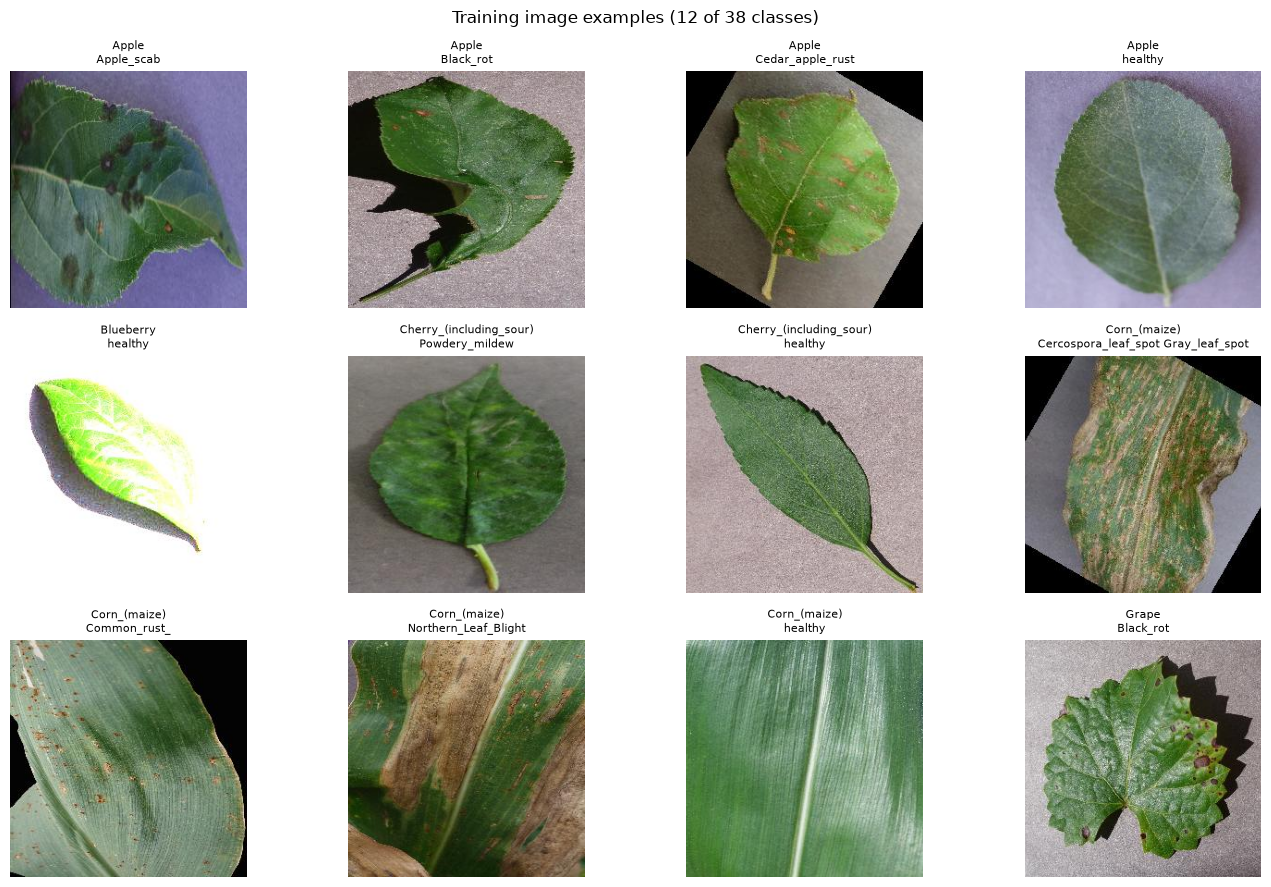

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from PIL import Image

# Resolve the project root whether the notebook kernel starts here or at the repo root.
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError(f"Could not find the project src folder from {Path.cwd()}")
sys.path.insert(0, str(ROOT / "src"))

TRAIN_DIR = ROOT / "data" / "processed" / "train"
VALID_DIR = ROOT / "data" / "processed" / "valid"
MODELS_DIR = ROOT / "models"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
train_classes = sorted((path for path in TRAIN_DIR.iterdir() if path.is_dir()), key=lambda path: path.name)
valid_classes = sorted(path.name for path in VALID_DIR.iterdir() if path.is_dir())
assert [path.name for path in train_classes] == valid_classes, "Train and validation classes do not match"
train_samples = [path for class_dir in train_classes for path in class_dir.iterdir() if path.suffix.lower() in image_extensions]
valid_samples = [path for class_dir in (VALID_DIR / name for name in valid_classes) for path in class_dir.iterdir() if path.suffix.lower() in image_extensions]

print(f"Classes: {len(train_classes)}")
print(f"Training images: {len(train_samples)}")
print(f"Validation images: {len(valid_samples)}")

# Show one real training image for each of the first 12 classes.
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, class_dir in zip(axes.flat, train_classes[:12]):
    image_path = next(path for path in class_dir.iterdir() if path.suffix.lower() in image_extensions)
    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(class_dir.name.replace("___", chr(10)), fontsize=8)
    ax.axis("off")
plt.suptitle("Training image examples (12 of 38 classes)")
plt.tight_layout()
plt.show()

## Train the classifier

This trains the ResNet18 classification head using all available training images and validates it against the validation split. Set `EPOCHS` higher and rerun this cell for a longer run.

In [6]:
import os
import subprocess
import sys

python_executable = Path(getattr(sys, "_base_executable", sys.executable))
if not python_executable.is_file():
    raise FileNotFoundError(f"Python executable not found: {python_executable}")

# Use the base interpreter so training also works when the selected notebook kernel is a broken venv.
training_code = (
    "import sys, torch; from pathlib import Path; "
    "root=Path(sys.argv[1]); sys.path.insert(0, str(root/'src')); "
    "from dataset import get_dataloaders; from model_transfer import get_resnet_model; from train import train_model; "
    "torch.set_num_threads(4) if not torch.cuda.is_available() else None; "
    "train_loader, valid_loader, classes=get_dataloaders(); "
    "model=get_resnet_model(num_classes=len(classes), freeze_base=True); "
    "device='cuda' if torch.cuda.is_available() else 'cpu'; "
    "print(f'Training on {device}; {len(classes)} classes; {len(train_loader.dataset)} training images; {len(valid_loader.dataset)} validation images', flush=True); "
    "train_model(model, train_loader, valid_loader, num_epochs=1, lr=0.001, device=device, model_name='resnet_transfer_exploration')"
)
training_environment = os.environ.copy()
training_environment["MPLBACKEND"] = "Agg"
process = subprocess.Popen(
    [str(python_executable), "-u", "-c", training_code, str(ROOT)],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    env=training_environment,
)
assert process.stdout is not None
for output_line in process.stdout:
    print(output_line, end="")
return_code = process.wait()
if return_code:
    raise subprocess.CalledProcessError(return_code, process.args)

Training on cpu; 38 classes; 11400 training images; 2850 validation images
Epoch 1/1 | Train Loss: 1.7293 Acc: 0.6173 | Val Loss: 0.8039 Acc: 0.8112 | LR: 1.00e-03 | Time: 895.7s
  -> Saved new best model (val_acc: 0.8112)
History saved -> C:\Users\akhil\Downloads\plant-disease-detector-main\plant-disease-detector-main\models\resnet_transfer_exploration_history.csv
Training curve saved -> C:\Users\akhil\Downloads\plant-disease-detector-main\plant-disease-detector-main\models\resnet_transfer_exploration_training_curve.png


## Training results

Load the saved epoch metrics and display the loss and accuracy curves.

In [5]:
import csv

history_path = MODELS_DIR / "resnet_transfer_exploration_history.csv"
with history_path.open(newline="", encoding="utf-8") as history_file:
    history = list(csv.DictReader(history_file))

epochs = [int(row["epoch"]) for row in history]
train_loss = [float(row["train_loss"]) for row in history]
valid_loss = [float(row["val_loss"]) for row in history]
train_acc = [float(row["train_acc"]) for row in history]
valid_acc = [float(row["val_acc"]) for row in history]
best_row = max(history, key=lambda row: float(row["val_acc"]))
print(f"Best validation accuracy: {float(best_row['val_acc']):.2%} (epoch {best_row['epoch']})")
print(f"Checkpoint: {MODELS_DIR / 'resnet_transfer_exploration_best.pth'}")

fig, (loss_ax, accuracy_ax) = plt.subplots(1, 2, figsize=(12, 4))
loss_ax.plot(epochs, train_loss, marker="o", label="Train")
loss_ax.plot(epochs, valid_loss, marker="o", label="Validation")
loss_ax.set(title="Loss", xlabel="Epoch")
loss_ax.legend()
loss_ax.grid(True)
accuracy_ax.plot(epochs, train_acc, marker="o", label="Train")
accuracy_ax.plot(epochs, valid_acc, marker="o", label="Validation")
accuracy_ax.set(title="Accuracy", xlabel="Epoch", ylabel="Fraction correct")
accuracy_ax.legend()
accuracy_ax.grid(True)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\akhil\\Downloads\\plant-disease-detector-main\\plant-disease-detector-main\\models\\resnet_transfer_exploration_history.csv'